# Tết in Vietnam and China, 1900 to 2100

Vietnam and China use the same rules for the lunar calendar, but Vietnam computes
them at UTC+7 and China at UTC+8. When a new moon falls between midnight in Beijing
and midnight in Hanoi (16:00 to 17:00 UT), the month starts one day earlier in
Vietnam. Sometimes that moves Tết (the Lunar New Year) itself, and in a few years
the leap month falls in a different place.

This notebook measures it with the [`nhatnguyet`](https://pypi.org/project/nhatnguyet/)
package (pure Python, no dependencies):

```bash
pip install nhatnguyet matplotlib
```

Data: Nhat Nguyet (nhatnguyet.org)

In [1]:
from datetime import date

import matplotlib.pyplot as plt
from nhatnguyet import to_lunar, to_solar

YEARS = range(1900, 2101)

# First day of the first lunar month, in each country's calendar.
tet = [(y, to_solar(y, 1, 1)["date"], to_solar(y, 1, 1, country="CN")["date"]) for y in YEARS]
differ = [(y, vn, cn) for y, vn, cn in tet if vn != cn]
print(f"Tết falls on a different day in {len(differ)} of {len(tet)} years:")
print("year  Vietnam     China")
for y, vn, cn in differ:
    print(f"{y}  {vn}  {cn}")

Tết falls on a different day in 10 of 201 years:
year  Vietnam     China
1903  1903-01-28  1903-01-29
1916  1916-02-03  1916-02-04
1935  1935-02-03  1935-02-04
1965  1965-02-01  1965-02-02
1968  1968-01-29  1968-01-30
1969  1969-02-16  1969-02-17
1985  1985-01-21  1985-02-20
2007  2007-02-17  2007-02-18
2030  2030-02-02  2030-02-03
2053  2053-02-18  2053-02-19


Nine of the ten differences are one day. **1985 is a whole month**, because the
leap month falls in a different place (see the leap month table below): China adds
a leap 10th month at the end of 1984, before Tết, while Vietnam adds a leap 2nd
month in 1985, after it. So on 21 January 1985 Vietnam starts the year of the Ox
while China is still in the 12th month of the year of the Rat:

In [2]:
for country in ("VN", "CN"):
    l = to_lunar("1985-01-21", country=country)
    print(country, f"{l['day']}/{l['month']}/{l['year']}", l["yearName"], l["zodiac"])

VN 1/1/1985 Yi Chou Ox
CN 1/12/1984 Jia Zi Rat


## The date of Tết, year by year

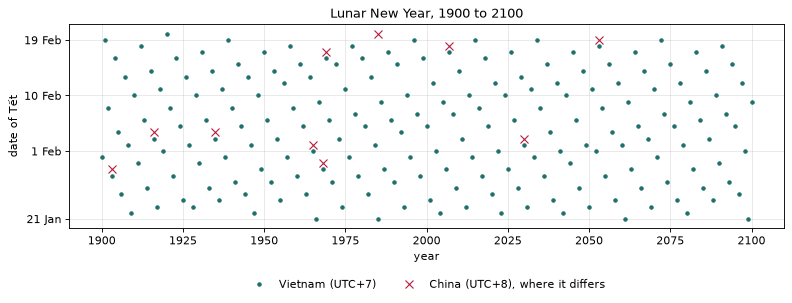

In [3]:
def day_of_year(iso):
    d = date.fromisoformat(iso)
    return (d - date(d.year, 1, 1)).days + 1

fig, ax = plt.subplots(figsize=(10, 4), dpi=80)
ax.plot([y for y, _, _ in tet], [day_of_year(vn) for _, vn, _ in tet], ".", color="#1f6f6b", label="Vietnam (UTC+7)")
ax.plot([y for y, _, _ in differ], [day_of_year(cn) for _, _, cn in differ], "x", color="#b91c3b", ms=8, label="China (UTC+8), where it differs")
ax.set_yticks([21, 32, 41, 50], ["21 Jan", "1 Feb", "10 Feb", "19 Feb"])
ax.set_xlabel("year")
ax.set_ylabel("date of Tết")
ax.set_title("Lunar New Year, 1900 to 2100")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Every lunar month and the leap months

Tết is one month in thirteen. Compare the first day of every lunar month
(including leap months) and the position of the leap month:

In [4]:
def leap_month(year, country):
    for m in range(1, 13):
        try:
            to_solar(year, m, 1, leap=True, country=country)
            return m
        except ValueError:  # no such leap month this year
            pass
    return None

starts = {"VN": {}, "CN": {}}
for country in starts:
    for y in YEARS:
        for m in range(1, 13):
            for leap in (False, True):
                try:
                    starts[country][(y, m, leap)] = to_solar(y, m, 1, leap=leap, country=country)["date"]
                except ValueError:
                    pass

months = sorted(set(starts["VN"]) | set(starts["CN"]))
moved = [k for k in months if starts["VN"].get(k) != starts["CN"].get(k)]
print(f"{len(moved)} of {len(months)} lunar months start on a different day (or exist in only one calendar)")

print("\nyears where the leap month differs:")
for y in YEARS:
    vn, cn = leap_month(y, "VN"), leap_month(y, "CN")
    if vn != cn:
        print(f"{y}  Vietnam: {vn or 'none':>4}  China: {cn or 'none':>4}")

99 of 2491 lunar months start on a different day (or exist in only one calendar)

years where the leap month differs:
1917  Vietnam:    3  China:    2
1922  Vietnam:    6  China:    5
1938  Vietnam:    8  China:    7


1984  Vietnam: none  China:   10
1985  Vietnam:    2  China: none
1987  Vietnam:    7  China:    6


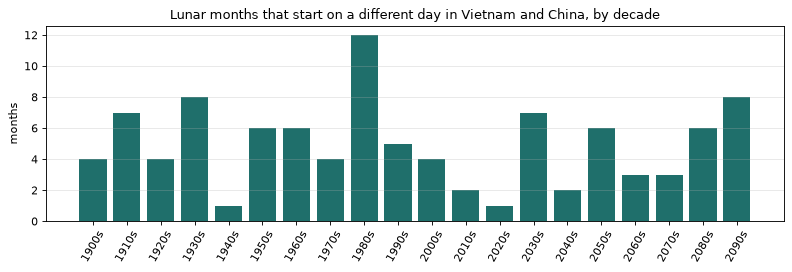

In [5]:
decades = list(range(1900, 2100, 10))
counts = [sum(1 for y, _, _ in moved if d <= min(y, 2099) < d + 10) for d in decades]  # 2100 counts in the 2090s

fig, ax = plt.subplots(figsize=(10, 3.5), dpi=80)
ax.bar([f"{d}s" for d in decades], counts, color="#1f6f6b")
ax.set_ylabel("months")
ax.set_title("Lunar months that start on a different day in Vietnam and China, by decade")
ax.tick_params(axis="x", labelrotation=60)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## What this means for software

- A lunar calendar library written for China gives the wrong Vietnamese date on
  those days, and the wrong Tết in the years above.
- Pass the country explicitly. `nhatnguyet` defaults to Vietnam;
  `country="CN"` (also `"KR"`, `"JP"`, `"TW"`...) gives the other calendars with the
  same rules, so the difference is only the time zone.
- The same package computes Zi Wei Dou Shu (`cast_zi_wei`), BaZi (`cast_bazi`) and
  numerology on the chosen calendar.

Data: Nhat Nguyet (nhatnguyet.org)